# RQ2: Intent validation

Rebuilds the numbers behind Fig. 3 and the RQ2 text of the paper from the released result files in `results/` (tier A: no model, no GPU).
A model **rejects** an intent when its answer is an empty SLO set (an unparseable answer counts as a rejection too, because it configures nothing).
The rejection rate rho is the share of the 195 invalid intents rejected. In the code the setups are called `zs3`, `fs3`, `zs3 CoT`, `fs3 CoT`; the paper writes `zs`, `fs`, `zs-cot`, `fs-cot`.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
RES = Path("results")
rho = pd.read_csv(RES / "I-01_rejection_rate_per_category.csv").set_index(["model", "prompt"])
cnt = pd.read_csv(RES / "I-02_counts_rejected.csv").set_index(["model", "prompt"])
overall = rho["overall"].unstack("prompt")[["zs3", "fs3", "zs3 CoT", "fs3 CoT"]]
display(overall.round(3))

prompt,zs3,fs3,zs3 CoT,fs3 CoT
model,,,,
Gemma4-E2B,0.123,0.021,0.662,0.877
Gemma4-E4B,0.800,0.882,0.744,0.938
Granite-4.1-3B,0.174,0.379,0.636,0.774
Granite-4.1-8B,0.215,0.862,0.554,0.774
Llama-3.1-8B,0.010,0.128,0.246,0.446
Llama-3.2-3B,0.000,0.031,0.149,0.144
Ministral-3-3B,0.415,0.687,0.774,0.887
Ministral-3-8B,0.246,0.677,0.744,0.954
Qwen3.5-4B,0.651,0.908,0.892,0.979


## Fig. 3 (as printed in the paper)

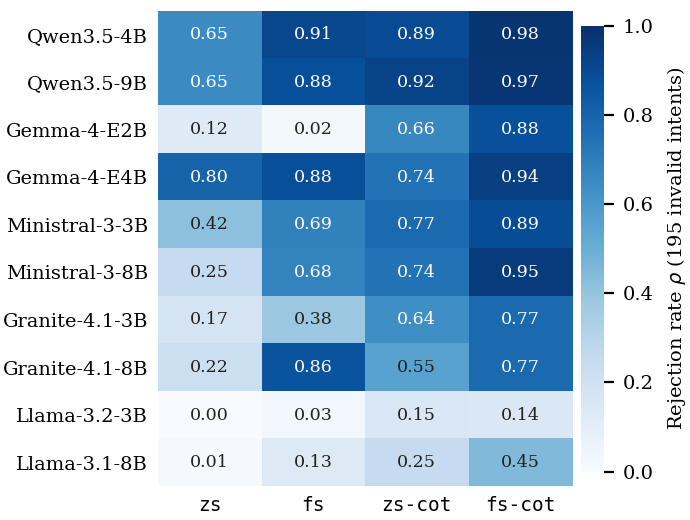

In [2]:
display(Image("figures/fig3_opt_i_heatmap.png", width=420))

## Checks against the sentences of Section IV-B
A failed assertion would mean the text and the data disagree.

In [3]:
top = cnt.xs("fs3 CoT", level="prompt")["overall"].sort_values(ascending=False)
print("fs-cot rejects of 195:", top.head(4).to_dict())
assert list(top.head(4).values) == [191, 190, 186, 183]
zs = overall["zs3"]
print("zs range:", round(zs.min(), 3), zs.idxmin(), "to", round(zs.max(), 3), zs.idxmax(), "| above 0.6:", list(zs[zs > 0.6].index))
assert zs.min() == 0 and zs.idxmin() == "Llama-3.2-3B" and round(zs.max(), 2) == 0.80 and (zs > 0.6).sum() == 3
gain = overall["fs3 CoT"] - zs
print("fs-cot minus zs:", round(gain.min(), 3), "to", round(gain.max(), 3))
assert (gain > 0).all() and round(gain.min(), 2) == 0.14 and round(gain.max(), 2) == 0.75

fs-cot rejects of 195: {'Qwen3.5-4B': 191, 'Qwen3.5-9B': 190, 'Ministral-3-8B': 186, 'Gemma4-E4B': 183}
zs range: 0.0 Llama-3.2-3B to 0.8 Gemma4-E4B | above 0.6: ['Gemma4-E4B', 'Qwen3.5-4B', 'Qwen3.5-9B']
fs-cot minus zs: 0.138 to 0.754


In [4]:
kinds = pd.read_csv(RES / "I-05_conflicting_rejected_per_kind.csv")
ec = "edge + cloud both required"
print("edge + cloud, zs:", kinds[kinds.prompt == "zs3"][ec].tolist(), "| best of any setup:", kinds[ec].max(),
      kinds.loc[kinds[ec].idxmax(), ["model", "prompt"]].tolist())
assert (kinds[kinds.prompt == "zs3"][ec] == 0).all() and kinds[ec].max() == 10
f = kinds[(kinds.prompt == "fs3 CoT") & kinds.model.isin(["Qwen3.5-4B", "Qwen3.5-9B", "Ministral-3-8B"])]
print(f[["model", "highest + lowest", "upper bound below lower bound"]].to_string(index=False))
assert (f["highest + lowest"] == 15).all() and (f["upper bound below lower bound"] == 12).all()

edge + cloud, zs: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] | best of any setup: 10.0 ['Ministral-3-8B', 'fs3 CoT']
         model  highest + lowest  upper bound below lower bound
    Qwen3.5-4B              15.0                           12.0
    Qwen3.5-9B              15.0                           12.0
Ministral-3-8B              15.0                           12.0


In [5]:
fr = pd.read_csv(RES / "I-06_trade_off.csv")
col = "false rejects of valid (count)"
non_cot = fr[fr.prompt.isin(["zs3", "fs3"])][col].max()
cot = fr[fr.prompt.isin(["zs3 CoT", "fs3 CoT"])]
w = cot.loc[cot[col].idxmax()]
print("false rejects of the 521 valid intents: without reasoning max", non_cot, "| with reasoning max", w[col], f"({w[col] / 521:.1%})", w["model"], w["prompt"])
assert non_cot == 0 and w["model"] == "Granite-4.1-3B" and w[col] == 36
assert (cot[cot.model.isin(["Qwen3.5-9B", "Ministral-3-8B"])][col] == 0).all()

false rejects of the 521 valid intents: without reasoning max 0 | with reasoning max 36 (6.9%) Granite-4.1-3B fs3 CoT


In [6]:
ct = pd.read_csv(RES / "I-09_content_type_of_accepted_answers.csv", index_col="category")
print("answers that contain SLOs (false accepts):", int(ct.values.sum()), "of", 40 * 195)
share = (ct["placement only"] / ct.sum(axis=1)).round(2)
print("single placement share per category:", share.to_dict())
assert int(ct.values.sum()) == 3351 and round(share.min() * 100) == 22 and round(share.max() * 100) == 50
halves = pd.read_csv(RES / "I-09_conflicting_what_happened_to_the_contradiction.csv", index_col="conflict halves")
print("conflicting answers with both halves of the contradiction:", int(halves.loc["both halves"].sum()))
assert int(halves.loc["both halves"].sum()) == 363

answers that contain SLOs (false accepts): 3351 of 7800
single placement share per category: {'ambiguous': 0.36, 'conflicting': 0.48, 'malformed': 0.22, 'unsupported': 0.5}
conflicting answers with both halves of the contradiction: 363


The 363 uses the grouping of the original analysis: the 10 conflicting intents that combine two kinds of conflict are a separate group (`mixed kind`) and are not counted as "both halves". The categories of this table come from keyword rules and are approximate.